In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [10]:
INTERIM_DIR = Path("../data/interim")
df = pd.read_csv(INTERIM_DIR / "atp_all_matches_with_features.csv")

df["tourney_date"] = pd.to_datetime(df["tourney_date"], format="mixed")

df = df[df["tourney_date"] >= "1990-01-01"]

df = df[df["tourney_level"].isin(['G', 'M', 'A', 'F'])].copy()

In [11]:
df = df.dropna(subset= ["winner_age", "loser_age"]).copy()

In [12]:
winner_rows = pd.DataFrame({
    "age": df["winner_age"],
    "played": 1,
    "won": 1
})

loser_rows = pd.DataFrame({
    "age": df["loser_age"],
    "played": 1,
    "won": 0
})

In [14]:
age_df = pd.concat([winner_rows, loser_rows], ignore_index=True)

In [16]:
age_stats = (
    age_df.groupby("age", as_index=False).agg(
        games=("played", "sum"),
        wins =("won", "sum")
    )
)

In [17]:
age_stats["winrate"] = age_stats["wins"] / age_stats["games"]
MIN_GAMES = 50
age_stats_plot = age_stats[age_stats["games"] >= MIN_GAMES].copy()

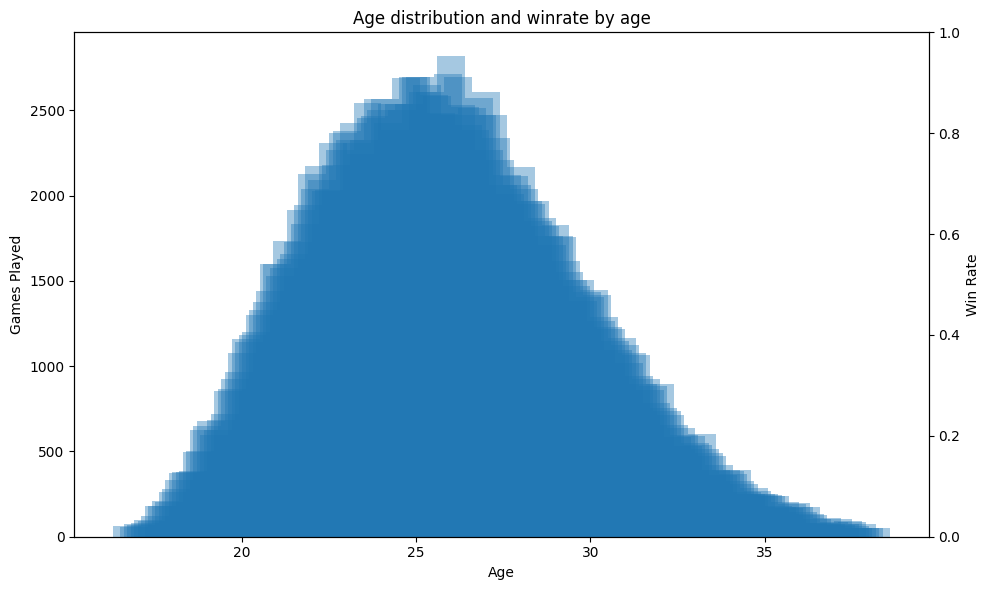

,age,games,wins,winrate
22,16.7,61,16,0.262295
24,16.9,56,9,0.160714
25,17.0,76,20,0.263158
26,17.1,70,15,0.214286
27,17.2,79,13,0.164557
28,17.3,97,20,0.206186
29,17.4,90,25,0.277778
30,17.5,122,32,0.262295
31,17.6,183,71,0.387978
32,17.7,183,73,0.398907


In [19]:
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.bar(age_stats_plot["age"], age_stats_plot["games"], alpha= 0.4)
ax1.set_xlabel("Age")
ax1.set_ylabel("Games Played")

ax2 =ax1.twinx()
ax2.plot(age_stats_plot["age"], age_stats_plot["games"], alpha = 0.4)
ax2.set_ylabel("Win Rate")
ax2.set_ylim(0, 1)

plt.title("Age distribution and winrate by age")
plt.tight_layout()
plt.show()

age_stats_plot.sort_values("age").head(20)



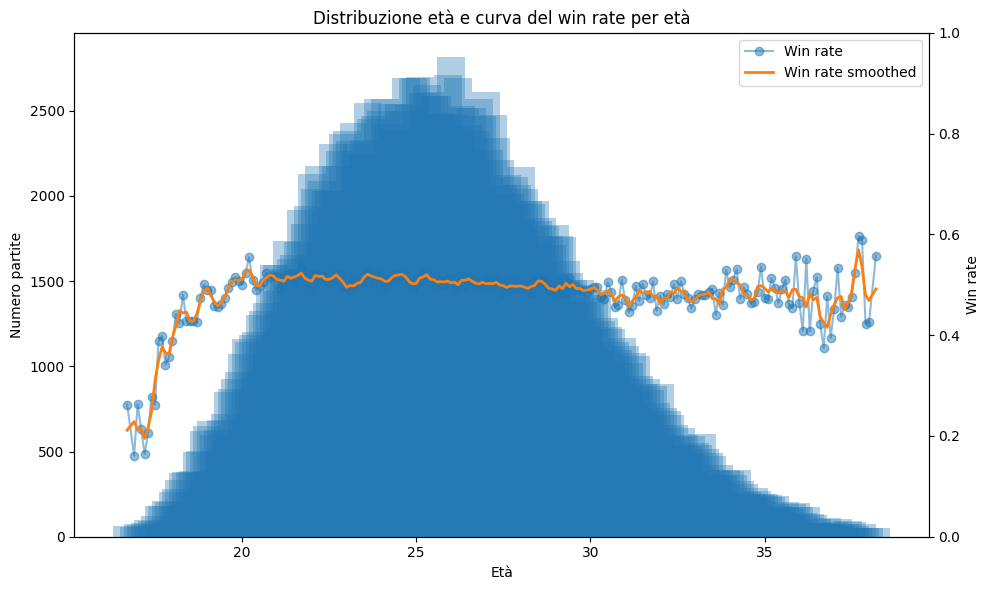

In [20]:
age_stats_plot = age_stats_plot.sort_values("age").copy()
age_stats_plot["winrate_smooth"] = age_stats_plot["winrate"].rolling(
    window=3, center=True, min_periods=1
).mean()

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.bar(age_stats_plot["age"], age_stats_plot["games"], alpha=0.35)
ax1.set_xlabel("Età")
ax1.set_ylabel("Numero partite")

ax2 = ax1.twinx()
ax2.plot(age_stats_plot["age"], age_stats_plot["winrate"], marker="o", alpha=0.5, label="Win rate")
ax2.plot(age_stats_plot["age"], age_stats_plot["winrate_smooth"], linewidth=2, label="Win rate smoothed")
ax2.set_ylabel("Win rate")
ax2.set_ylim(0, 1)
ax2.legend()

plt.title("Distribuzione età e curva del win rate per età")
plt.tight_layout()
plt.show()